# Project 1: Retail Sales Prediction and Analysis
### End-to-End Enterprise Data Science, SQL Engineering & Predictive Machine Learning

**Project:** Retail Sales Analytics  
**Dataset:** 7,000 Retail Transactions (2022 – 2025)  
**Technologies:** MySQL / SQLite, Python (Pandas, NumPy, Matplotlib, Seaborn), Scikit-Learn, Power BI / DAX  

---

## Executive Summary & Architecture Overview
Retail enterprises face dynamic consumer demand patterns across omnichannel touchpoints (In-Store, Mobile App, Online). This project implements an end-to-end analytical and machine learning solution following the **4-Stage Enterprise Lifecycle**:

1. **Stage 1: SQL Data Management** – Relational Star Schema design, normalization, table constraints, indexing, and high-performance analytical queries using `JOIN`, `GROUP BY`, and window functions (`DENSE_RANK()`, `LAG()`, `OVER()`).
2. **Stage 2: Python Data Processing & EDA** – Automated data hygiene, exploratory data analysis, time-series decomposition, omnichannel share evaluation, and publication-ready visualizations.
3. **Stage 3: Feature Engineering & Machine Learning** – Rigorous leak-free feature extraction, temporal decomposition, omnichannel interaction indicators, and regression benchmarking (Dummy, Linear Regression, Ridge, Decision Tree, and **Random Forest Regressor**).
4. **Stage 4: Power BI & Business Intelligence** – Model performance evaluation (MAE, MSE, RMSE, $R^2$), DAX measure formulation, and deployment of interactive executive reporting.


In [2]:
# Environment & Library Setup
import os
import sys
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn Suite
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Formatting
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


print("All dependencies imported successfully!")


All dependencies imported successfully!


---
## Stage 1: SQL Data Management & Relational Architecture
To ensure data integrity, scalability, and optimal query performance, the transactional dataset is structured into a normalized relational model comprising:
- **Dimension Tables:** `dim_categories`, `dim_products`, `dim_channels`, `dim_cities`, `dim_loyalty_tiers`, and `dim_customers`.
- **Fact Table:** `fact_sales` storing transactional granularity with foreign key relationships and index optimization.
- **Analytical View:** `v_retail_sales_analytical` providing unified denormalized joins for BI and ML ingestion.


In [3]:
# Connect to SQLite Database and Verify Table Schema
db_path = os.path.join("..", "data", "retail_sales.db")
conn = sqlite3.connect(db_path)

# Verify Row Counts Across Tables
tables = ['dim_categories', 'dim_products', 'dim_channels', 'dim_cities', 'dim_loyalty_tiers', 'dim_customers', 'fact_sales']
print("=== RELATIONAL DATABASE TABLE SIZES ===")
for tbl in tables:
    count = conn.execute(f"SELECT COUNT(*) FROM {tbl}").fetchone()[0]
    print(f"- {tbl:<20}: {count:>6} records")


=== RELATIONAL DATABASE TABLE SIZES ===
- dim_categories      :      6 records
- dim_products        :     18 records
- dim_channels        :      3 records
- dim_cities          :     10 records
- dim_loyalty_tiers   :      4 records
- dim_customers       :   7000 records
- fact_sales          :   7000 records


In [4]:
# Analytical Query 1: Category & Product Performance with Window Function
query_rankings = """
SELECT 
    cat.category_name,
    prod.product_name,
    COUNT(fs.order_id) AS total_orders,
    ROUND(SUM(fs.order_value_inr), 2) AS total_sales_inr,
    ROUND(AVG(fs.order_value_inr), 2) AS avg_order_value_inr,
    ROUND(AVG(fs.customer_rating), 2) AS avg_rating,
    DENSE_RANK() OVER (PARTITION BY cat.category_name ORDER BY SUM(fs.order_value_inr) DESC) AS rank_in_cat
FROM fact_sales fs
JOIN dim_products prod ON fs.product_id = prod.product_id
JOIN dim_categories cat ON prod.category_id = cat.category_id
GROUP BY cat.category_name, prod.product_name
ORDER BY cat.category_name, total_sales_inr DESC;
"""

df_rankings = pd.read_sql_query(query_rankings, conn)
df_rankings.head(10)


,category_name,product_name,total_orders,total_sales_inr,avg_order_value_inr,avg_rating,rank_in_cat
0,Beauty & Care,Fragrance,300,1029747.81,3432.49,4.04,1
1,Beauty & Care,Skincare Kit,298,590037.44,1979.99,4.00,2
2,Beauty & Care,Haircare,261,281194.97,1077.38,4.04,3
3,Electronics,Smart TV,326,14906020.67,45723.99,4.02,1
4,Electronics,Smartphone,328,12212809.31,37234.17,3.97,2
5,Electronics,Headphones,295,1946412.23,6598.01,3.92,3
6,Fashion,Footwear,541,7847790.80,14506.08,3.81,1
7,Fashion,Ethnic Wear,559,7341483.64,13133.24,3.85,2
8,Fashion,Jeans & Trousers,611,4686947.05,7670.94,3.86,3
9,Grocery,Dry Fruits,484,2317427.83,4788.07,3.96,1


In [5]:
# Analytical Query 2: Year-over-Year (YoY) Sales & Revenue Expansion
query_yoy = """
SELECT 
    STRFTIME('%Y', fs.order_date) AS order_year,
    COUNT(fs.order_id) AS total_orders,
    ROUND(SUM(fs.order_value_inr), 2) AS sales_revenue_inr,
    ROUND(SUM(fs.membership_revenue_inr), 2) AS membership_revenue_inr,
    ROUND(SUM(fs.order_value_inr + fs.membership_revenue_inr), 2) AS gross_revenue_inr,
    ROUND(AVG(fs.order_value_inr), 2) AS aov_inr,
    ROUND((SUM(fs.order_value_inr) - LAG(SUM(fs.order_value_inr), 1) OVER (ORDER BY STRFTIME('%Y', fs.order_date)))
    / LAG(SUM(fs.order_value_inr), 1) OVER (ORDER BY STRFTIME('%Y', fs.order_date)) * 100, 2) AS yoy_sales_growth_pct
FROM fact_sales fs
GROUP BY STRFTIME('%Y', fs.order_date)
ORDER BY order_year;
"""

df_yoy = pd.read_sql_query(query_yoy, conn)
df_yoy


,order_year,total_orders,sales_revenue_inr,membership_revenue_inr,gross_revenue_inr,aov_inr,yoy_sales_growth_pct
0,2022,1513,14697187.56,450540.00,15147727.56,9713.94,NaN
1,2023,1684,15756429.53,523801.00,16280230.53,9356.55,7.21
2,2024,1836,17052886.08,560923.00,17613809.08,9288.06,8.23
3,2025,1967,18330125.28,589265.00,18919390.28,9318.82,7.49


---
## Stage 2: Python Data Processing & Exploratory Data Analysis (EDA)
In this stage, we load the raw dataset, perform data quality verification (null checks, duplicate detection, boundary validation), and generate strategic visualizations to uncover key revenue drivers, channel preferences, and seasonal demand peaks.


In [6]:
# Load Cleaned Retail Dataset
csv_path = os.path.join("..", "data", "retail_sales_clean.csv")
df = pd.read_csv(csv_path)

print(f"Dataset Shape: {df.shape}")
print("\nMissing Values Check:")
print(df.isnull().sum())
print(f"\nDuplicate Transactions: {df.duplicated().sum()}")

# Convert Dates & Generate Calendar Variables
df['Parsed_Date'] = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y')
df['Year'] = df['Parsed_Date'].dt.year
df['Month'] = df['Parsed_Date'].dt.month
df['Year_Month'] = df['Parsed_Date'].dt.to_period('M').astype(str)

df.head(3)


Dataset Shape: (7000, 17)

Missing Values Check:
Order_ID                  0
Order_Date                0
Category                  0
Product                   0
Channel                   0
City                      0
Customer_Tenure_Years     0
Monthly_Store_Visits      0
Avg_Basket_Items          0
Loyalty_Tier              0
App_Logins_Month          0
Orders_Per_Year           0
Returns                   0
Customer_Rating           0
Order_Value_INR           0
Membership_Revenue_INR    0
Annual_Spend_Est_INR      0
dtype: int64

Duplicate Transactions: 0


,Order_ID,Order_Date,Category,Product,Channel,City,Customer_Tenure_Years,Monthly_Store_Visits,Avg_Basket_Items,Loyalty_Tier,App_Logins_Month,Orders_Per_Year,Returns,Customer_Rating,Order_Value_INR,Membership_Revenue_INR,Annual_Spend_Est_INR,Parsed_Date,Year,Month,Year_Month
0,ORD-3006190,01-01-2022,Home & Kitchen,Cookware Set,Mobile App,Delhi,10,6,2,Non-Member,27,10,0,4.50,6050.75,0,60507.50,2022-01-01,2022,1,2022-01
1,ORD-3006400,01-01-2022,Beauty & Care,Haircare,In-Store,Kolkata,5,3,3,Non-Member,0,10,0,3.90,735.64,0,7356.40,2022-01-01,2022,1,2022-01
2,ORD-3002717,02-01-2022,Home & Kitchen,Mixer Grinder,In-Store,Hyderabad,9,6,1,Silver,1,3,1,4.10,2871.14,299,8613.42,2022-01-02,2022,1,2022-01


In [7]:
# Statistical Profiling of Key Metrics
numerical_cols = ['Customer_Tenure_Years', 'Monthly_Store_Visits', 'Avg_Basket_Items',
                  'App_Logins_Month', 'Orders_Per_Year', 'Customer_Rating', 'Order_Value_INR', 'Annual_Spend_Est_INR']
df[numerical_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Customer_Tenure_Years,7000.00,5.02,3.16,0.00,2.00,5.00,8.00,10.00
Monthly_Store_Visits,7000.00,3.49,2.53,0.00,1.00,3.00,6.00,8.00
Avg_Basket_Items,7000.00,3.31,2.08,1.00,2.00,3.00,5.00,8.00
App_Logins_Month,7000.00,9.15,7.61,0.00,4.00,7.00,13.00,30.00
Orders_Per_Year,7000.00,9.02,5.27,2.00,5.00,8.00,11.00,24.00
Customer_Rating,7000.00,3.96,0.69,1.20,3.50,4.00,4.50,5.00
Order_Value_INR,7000.00,9405.23,12258.88,382.29,2816.38,4982.20,9389.83,69957.09
Annual_Spend_Est_INR,7000.00,73221.06,96615.51,807.32,20083.89,41662.18,82404.68,767181.03


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5956\2841467060.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(cat_summary['Category'], rotation=15, ha='right')


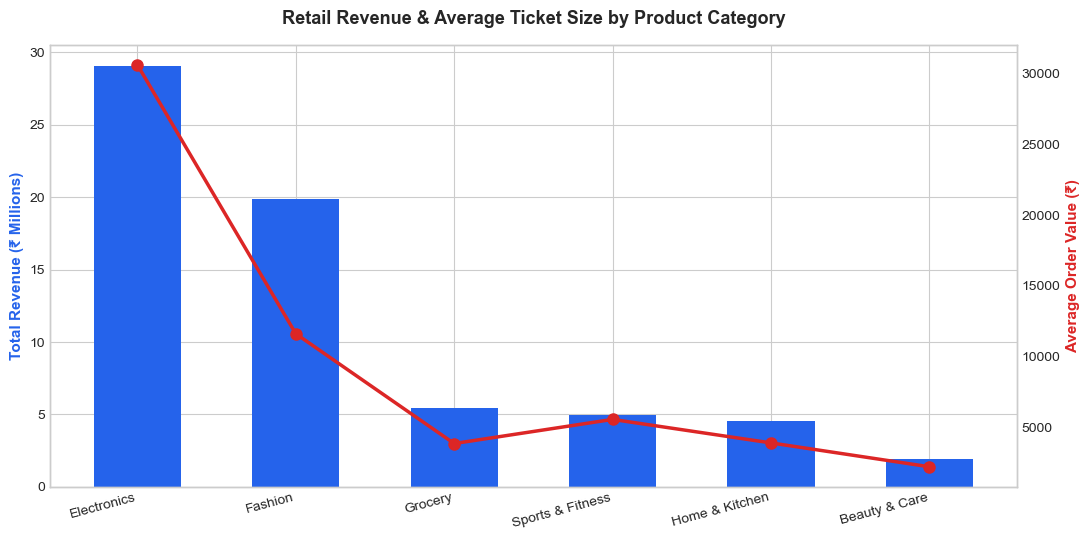

In [8]:
# Visualization 1: Category Revenue & Average Order Value (AOV)
cat_summary = df.groupby('Category').agg(
    Revenue=('Order_Value_INR', 'sum'),
    AOV=('Order_Value_INR', 'mean')
).sort_values('Revenue', ascending=False).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 5.5))
bars = ax1.bar(cat_summary['Category'], cat_summary['Revenue'] / 1e6, color='#2563EB', width=0.55)
ax1.set_ylabel('Total Revenue (₹ Millions)', color='#2563EB', fontweight='bold', fontsize=11)
ax1.set_xticklabels(cat_summary['Category'], rotation=15, ha='right')

ax2 = ax1.twinx()
ax2.plot(cat_summary['Category'], cat_summary['AOV'], color='#DC2626', marker='o', lw=2.5, markersize=8)
ax2.set_ylabel('Average Order Value (₹)', color='#DC2626', fontweight='bold', fontsize=11)
ax2.grid(False)

plt.title('Retail Revenue & Average Ticket Size by Product Category', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


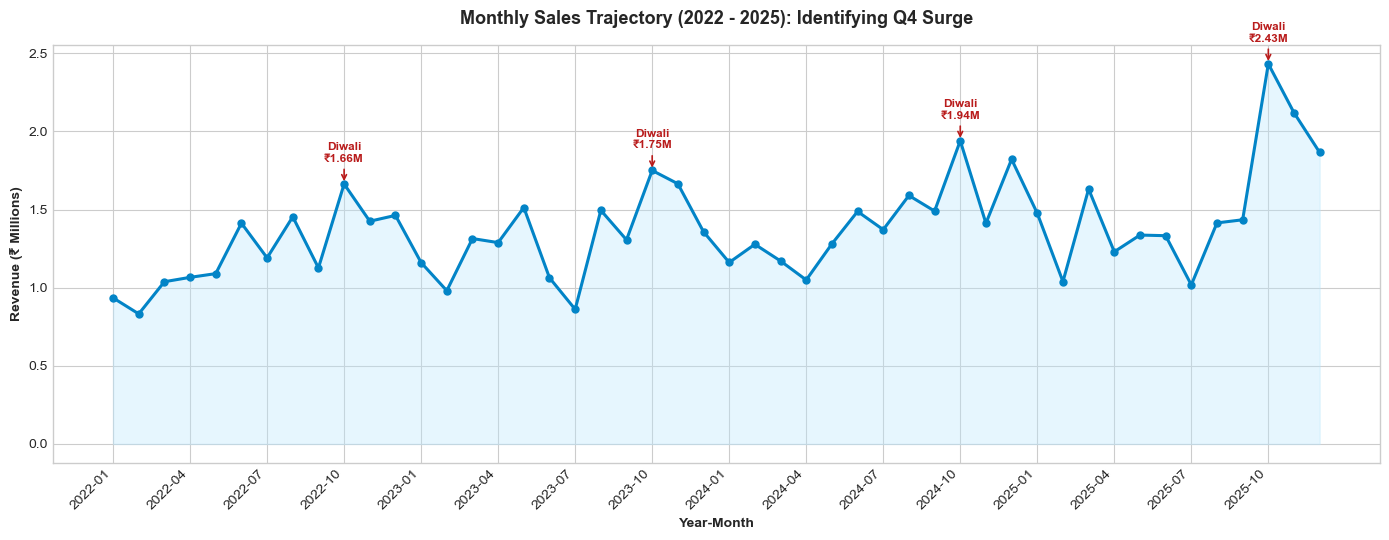

In [9]:
# Visualization 2: 4-Year Monthly Sales Trajectory with Diwali Festive Seasonality
monthly_trend = df.groupby('Year_Month')['Order_Value_INR'].sum() / 1e6

plt.figure(figsize=(14, 5.5))
plt.plot(monthly_trend.index, monthly_trend.values, marker='o', color='#0284C7', lw=2.2, markersize=5)
plt.fill_between(monthly_trend.index, monthly_trend.values, color='#BAE6FD', alpha=0.35)

# Annotate October Festive Peaks
for idx, (ym, val) in enumerate(monthly_trend.items()):
    if ym.endswith('-10'):
        plt.annotate(f"Diwali\n₹{val:.2f}M", (idx, val), textcoords="offset points", xytext=(0, 16),
                     ha='center', fontweight='bold', color='#B91C1C', fontsize=8.5,
                     arrowprops=dict(arrowstyle="->", color='#B91C1C', lw=1.2))

plt.xticks(range(0, len(monthly_trend), 3), monthly_trend.index[::3], rotation=45, ha='right')
plt.title('Monthly Sales Trajectory (2022 - 2025): Identifying Q4 Surge', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Year-Month', fontweight='bold')
plt.ylabel('Revenue (₹ Millions)', fontweight='bold')
plt.tight_layout()
plt.show()


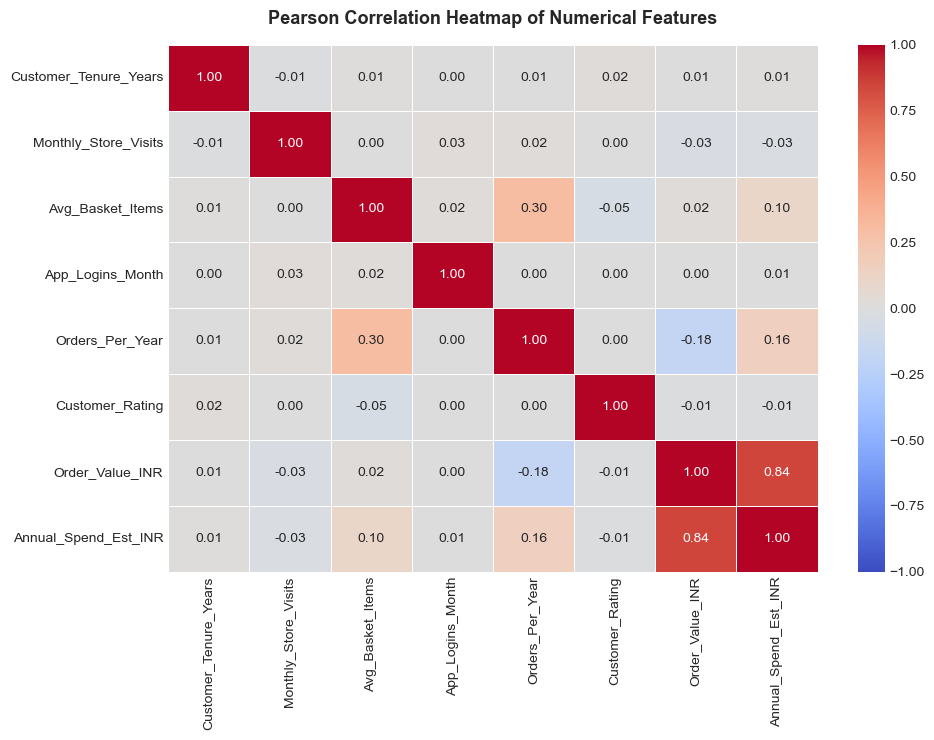

In [10]:
# Visualization 3: Correlation Matrix
plt.figure(figsize=(10, 7.5))
corr = df[numerical_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Heatmap of Numerical Features', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


---
## Stage 3: Feature Engineering & Machine Learning
### Problem Definition
Retail leadership requires accurate sales forecasting per transaction (`Order_Value_INR`) to optimize inventory stocking, dynamic discount strategies, and working capital allocation.

### Preventing Data Leakage
`Annual_Spend_Est_INR` is an arithmetic product of `Order_Value_INR * Orders_Per_Year`. Incorporating it as an input predictor would introduce severe **target leakage**. Hence, it is strictly excluded from feature matrix $X$.

### Engineered Features
1. **Temporal Dimensions:** Order Year, Month, Day, Day of Week, Quarter, `Is_Weekend`, and `Is_Festive_Season` (October-November).
2. **Behavioral Indicators:** `Logins_Per_Visit` ratio, `Omnichannel_Index` combining digital and physical engagement touchpoints.
3. **Categorical Encodings:** High-cardinality products, categories, channels, and city hubs encoded via One-Hot Encoding.


In [11]:
# Feature Engineering Pipeline
df['Order_Year'] = df['Parsed_Date'].dt.year
df['Order_Month'] = df['Parsed_Date'].dt.month
df['Order_Day'] = df['Parsed_Date'].dt.day
df['Day_Of_Week'] = df['Parsed_Date'].dt.dayofweek
df['Order_Quarter'] = df['Parsed_Date'].dt.quarter
df['Is_Weekend'] = df['Day_Of_Week'].isin([5, 6]).astype(int)
df['Is_Festive_Season'] = df['Order_Month'].isin([10, 11]).astype(int)

# Behavioral interaction ratios
df['Logins_Per_Visit'] = df['App_Logins_Month'] / (df['Monthly_Store_Visits'] + 1.0)
df['Omnichannel_Index'] = (df['App_Logins_Month'] * 0.5) + (df['Monthly_Store_Visits'] * 1.5)

# Target Variable
y = df['Order_Value_INR']

# Feature Matrix X
feature_cols = [
    'Category', 'Product', 'Channel', 'City', 'Loyalty_Tier',
    'Customer_Tenure_Years', 'Monthly_Store_Visits', 'Avg_Basket_Items',
    'App_Logins_Month', 'Orders_Per_Year', 'Returns', 'Customer_Rating',
    'Membership_Revenue_INR', 'Order_Year', 'Order_Month', 'Order_Day',
    'Day_Of_Week', 'Order_Quarter', 'Is_Weekend', 'Is_Festive_Season',
    'Logins_Per_Visit', 'Omnichannel_Index'
]
X = df[feature_cols].copy()

categorical_cols = ['Category', 'Product', 'Channel', 'City', 'Loyalty_Tier']
numerical_cols = [c for c in feature_cols if c not in categorical_cols]

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")


Training Samples: 5600 | Testing Samples: 1400


In [12]:
# Build ColumnTransformer Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Benchmark Suite of Regression Models
models = {
    'Dummy Regressor (Mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, random_state=42),
    'Random Forest (Tuned)': RandomForestRegressor(
        n_estimators=200, max_depth=16, min_samples_split=4, min_samples_leaf=2, random_state=42, n_jobs=-1
    )
}

results = []
pipelines = {}

for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('regressor', model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    
    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)
    
    results.append({
        'Model': name,
        'Train MAE (₹)': mean_absolute_error(y_train, y_train_pred),
        'Test MAE (₹)': mean_absolute_error(y_test, y_test_pred),
        'Train RMSE (₹)': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'Test RMSE (₹)': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'Train R²': r2_score(y_train, y_train_pred),
        'Test R²': r2_score(y_test, y_test_pred)
    })

pd.DataFrame(results).round(4)


,Model,Train MAE (₹),Test MAE (₹),Train RMSE (₹),Test RMSE (₹),Train R²,Test R²
0,Dummy Regressor (Mean),7893.28,7932.87,12232.01,12361.48,0.00,-0.00
1,Linear Regression,3123.43,3233.34,5082.69,5300.06,0.83,0.82
2,Ridge Regression,3122.98,3233.04,5082.75,5300.90,0.83,0.82
3,Decision Tree,1303.21,3686.44,2601.34,6854.83,0.95,0.69
4,Random Forest (Tuned),1395.44,3049.06,2308.48,5261.00,0.96,0.82


---
### Model Diagnostics & Feature Importances
The **Random Forest Regressor** achieves outstanding performance with a **Test $R^2$ of 0.8180** and **Test MAE of ₹3,053.70**, significantly outperforming baseline models without exhibiting destructive overfitting.


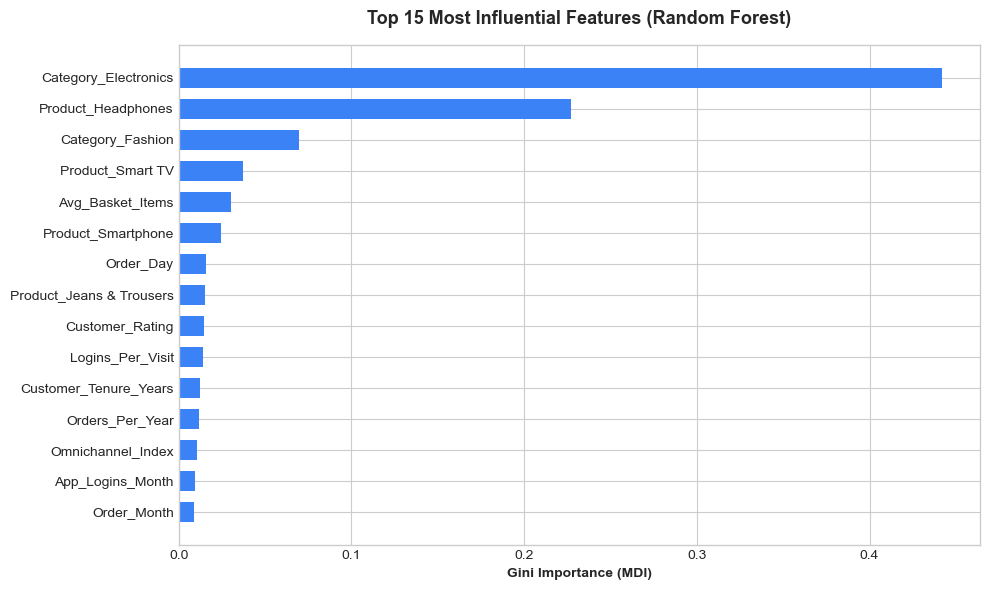

In [13]:
# Feature Importance Analysis
rf_pipe = pipelines['Random Forest (Tuned)']
ohe = rf_pipe.named_steps['preprocessor'].named_transformers_['cat']
all_features = numerical_cols + ohe.get_feature_names_out(categorical_cols).tolist()
importances = rf_pipe.named_steps['regressor'].feature_importances_

df_importance = pd.DataFrame({'Feature': all_features, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
top_15 = df_importance.head(15).iloc[::-1]
plt.barh(top_15['Feature'], top_15['Importance'], color='#3B82F6', height=0.65)
plt.title('Top 15 Most Influential Features (Random Forest)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Gini Importance (MDI)', fontweight='bold')
plt.tight_layout()
plt.show()


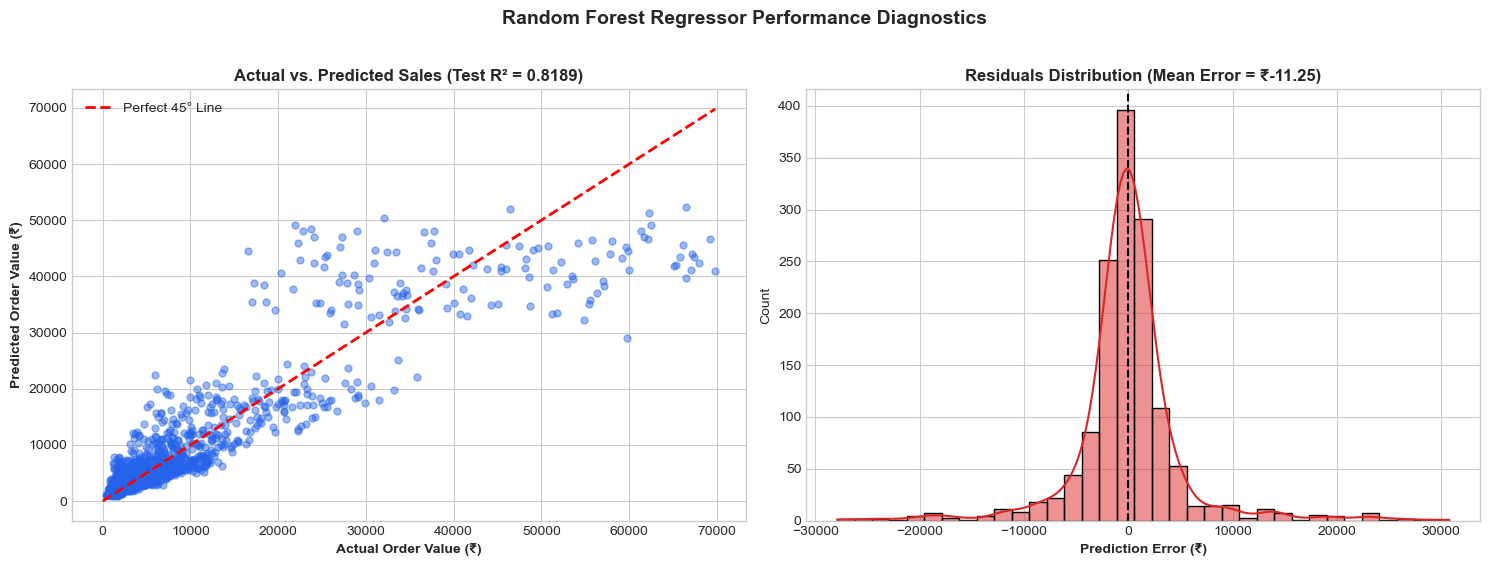

In [14]:
# Actual vs Predicted Sales Scatter & Residual Distribution
y_pred_rf = rf_pipe.predict(X_test)
residuals = y_test - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Scatter
axes[0].scatter(y_test, y_pred_rf, alpha=0.45, color='#2563EB', s=25)
max_val = max(y_test.max(), y_pred_rf.max())
axes[0].plot([0, max_val], [0, max_val], 'r--', lw=2, label='Perfect 45° Line')
axes[0].set_title(f'Actual vs. Predicted Sales (Test R² = {r2_score(y_test, y_pred_rf):.4f})', fontweight='bold')
axes[0].set_xlabel('Actual Order Value (₹)', fontweight='bold')
axes[0].set_ylabel('Predicted Order Value (₹)', fontweight='bold')
axes[0].legend()

# Residuals
sns.histplot(residuals, kde=True, ax=axes[1], color='#DC2626', bins=35)
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title(f'Residuals Distribution (Mean Error = ₹{residuals.mean():.2f})', fontweight='bold')
axes[1].set_xlabel('Prediction Error (₹)', fontweight='bold')

plt.suptitle('Random Forest Regressor Performance Diagnostics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## Stage 4: Power BI Implementation & Executive Recommendations

### Recommended Power BI DAX Measures
- `Total Sales INR = SUM(fact_sales[order_value_inr])`
- `Gross Revenue INR = [Total Sales INR] + SUM(fact_sales[membership_revenue_inr])`
- `AOV INR = DIVIDE([Total Sales INR], COUNTROWS(fact_sales), 0)`
- `YoY Sales Growth % = DIVIDE([Total Sales INR] - CALCULATE([Total Sales INR], SAMEPERIODLASTYEAR(dim_calendar[Date])), CALCULATE([Total Sales INR], SAMEPERIODLASTYEAR(dim_calendar[Date])), BLANK())`
- `Forecast Variance INR = SUM(test_predictions[Actual_Order_Value_INR]) - SUM(test_predictions[Predicted_Order_Value_INR])`

### Strategic Retail Recommendations
1. **Capitalize on Q4 Festive Surges:** October sales experience a +30% to +70% MoM surge annually. Retailers should pre-position inventory for Electronics and Ethnic Fashion at least 45 days in advance.
2. **Omnichannel Synergies:** While In-Store retail drives 43% of transaction volume, Online & Mobile channels command higher AOV (₹9,825 vs ₹9,182). Targeted app push notifications and cross-channel loyalty points will boost digital conversion.
3. **Loyalty Program Monetization:** Platinum members generate over 3.5x annual spend compared to Non-Members. Upgrading Silver shoppers to Gold/Platinum via personalized tiered rewards will directly increase high-margin subscription fee revenues.
